# Lista de Exercícios 1: Processos de Decisão de Markov e Programação Dinâmica

#### Disciplina: Aprendizado por Reforço
#### Professor: Luiz Chaimowicz
#### Monitor: Daniel Terra Gomes
---

## Instruções

- ***SUBMISSÕES QUE NÃO SEGUIREM AS INSTRUÇÕES A SEGUIR NÃO SERÃO AVALIADAS.***
- Leia atentamente toda a lista de exercícios e familiarize-se com o código fornecido antes de começar a implementação.
- Os locais onde você deverá escrever suas soluções estão demarcados com comentários `# YOUR CODE HERE` ou `YOUR ANSWER HERE`.
- **Não altere o código fora das áreas indicadas, nem adicione ou remova células. O nome deste arquivo também não deve ser modificado.**
- Antes de submeter, certifique-se de que o código esteja funcionando do início ao fim sem erros.
- Submeta apenas este notebook (*ps1.ipynb*) com as suas soluções no Moodle.
- Prazo de entrega: 23/09/2025. Submissões fora do prazo terão uma penalização de -20% da nota final por dia de atraso.
- Utilize a [documentação do Gymnasium](https://gymnasium.farama.org/) para auxiliar sua implementação.
- Em caso de dúvidas entre em contato pelo fórum "Dúvidas com relação aos exercícios e trabalho de curso" no moodle da Disciplina.

---

## Frozen Lake

O ambiente Frozen Lake é uma simulação clássica utilizada para treinamento de agentes em aprendizado por reforço. Neste ambiente, o agente navega por um lago congelado representado por um grid de tamanho $n \times m$, com o objetivo de alcançar um alvo. O lago contém dois tipos de células: (1) células com gelo sólido, que são seguras para o agente se mover, e (2) as células com buracos, nas quais o agente cai e falha a missão. Embora o Gymnasium já possua uma implementação do Frozen Lake, neste exercício iremos implementá-lo do zero.

No início de cada episódio, o agente é posicionado na célula $[0, 0]$ enquanto o alvo é posicionado na célula mais distante do agente, na posição $[n-1, m-1]$ em um mapa de tamanho $n \times m$. A cada passo, o agente recebe uma observação indicando sua posição atual no lago e tem a possibilidade de escolher entre quatro ações possíveis: mover-se para cima, para baixo, para a esquerda ou para a direita. No entanto, devido à superfície escorregadia do lago, ele nem sempre se move na direção desejada, podendo acabar se movendo em uma direção perpendicular à escolhida. O agente recebe uma recompensa de 1 se alcançar o alvo e zero em todos os outros estados. Um episódio termina quando o agente alcança o objetivo ou cai na água.

Neste exercício, vamos trabalhar sempre com o mesmo mapa $4 \times 4$, representado na figura abaixo.

![Frozen Lake Map](https://gymnasium.farama.org/_images/frozen_lake.gif)

Sua primeira tarefa será implementar o ambiente Frozen Lake utilizando o arcabouço fornecido pelo Gymnasium. Abaixo, você encontrará um código inicial que deverá ser utilizado em sua implementação. Siga essas instruções para garantir que seu código está de acordo com o esperado:

1. Na função `__init__`, já definimos o mapa que será utilizado e armazenamos essa informação na variável `_description`. Nesse mapa, a letra 'S' representa a posição inicial do agente, a letra 'G' indica o alvo, as letras 'F' representam gelo sólido (que é seguro) e as letras 'H' marcam os buracos. No entanto, ainda é necessário adicionar mais algumas informações no ambiente, especificamente sobre a representação das observações e das ações. Embora existam várias maneiras de representar os espaços de observações e de ação, neste exercício, você deve usar a forma mais simples possível, que pode ser representada por um único valor discreto. Na função `__init__`, defina o espaço de observações e o espaço de ações, atribuindo-os às variáveis `self.observation_space` e `self.action_space`, respectivamente. Utilize apenas a classe `gymnasium.spaces.Discrete` nesta tarefa.

2. Antes de prosseguirmos com as funcionalidades do gymnasium, vamos implementar algumas funções auxiliares para facilitar as próximas etapas. Implemente a função `_get_obs`, que retorna a observação atual do ambiente. Além disso, implemente a função `_set_state`, que recebe um valor inteiro correspondente a uma posição no lago e coloca o agente nesta localização.

3. A função `reset` deve resetar o ambiente e inicializar um novo episódio, posicionando o agente na célula $[0, 0]$ e fazendo todos os ajustes internos necessários. Esta função deve retornar uma tupla contendo a observação inicial e as informações do ambiente. Neste exercício, vamos retornar um dicionario vazio `{}` para as informações. Lembre-se que a observação deve ser um único valor discreto, como definido no item 1. Implemente a função `reset`.

4. A função `step()` é responsável por atualizar o ambiente com base na ação executada pelo agente. Ela recebe como entrada a ação escolhida pelo agente, um parâmetro seed e uma variável options, e calcula o novo estado atual com base na função de transição previamente definida. Neste exercício, você pode ignorar os parâmetros seed e options, pois não precisaremos deles. Neste ambiente que estamos desenvolvendo, o agente tem 80% de chance de se mover na direção desejada e 20% de chance de se mover em uma direção perpendicular à escolhida, distribuída igualmente entre os dois sentidos possíveis (10% para cada um). **As ações do agente devem ser representadas pelos valores 0 (mover-se para a esquerda), 1 (mover-se para baixo), 2 (mover-se para a direita) e 3 (mover-se para cima)**. Caso o agente tente se mover para fora do mapa, ele permanecerá na mesma posição. Além disso, a função atribui uma recompensa ao agente e verifica se o episódio chegou ao fim. Implemente a função step() para que ela retorne a observação do estado atual, a recompensa recebida, um valor booleano indicando se o estado é terminal, um valor booleano informando se o episódio foi truncado e as informações do ambiente. Esses dois últimos valores são necessários devidio à interface estabelecida pelo gymnasium, mas não se preocupe com eles; apenas retorne sempre `False` e `{}` para eles.

In [1]:
import sys
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt

In [2]:
class FrozenLake(gym.Env):
    def __init__(self):
        self._description = np.asarray([
            "SFFF",
            "FHFH",
            "FFFH",
            "HFFG"
        ], dtype='c')
        
        self.action_space = gym.spaces.Discrete(4)
        self.observation_space = gym.spaces.Discrete(16)
        self.s = 0

    def _get_obs(self):
        return self.s

    def _set_state(self, state):
        self.s = state

    def reset(self, seed = None, options = None):
        super().reset(seed=seed)
        self.s = 0
        return (int(self.s), {})

    def step(self, action):
        row = self.s // 4
        col = self.s % 4
        action_int = int(action)
        drawn_action = self.np_random.choice([1, 0], p = [0.8, 0.2])
        second_drawn_action = self.np_random.choice([1, 0], p = [0.5, 0.5])

        # 0: Mover para a esquerda
        if action_int == 0:
            if drawn_action == 1:
                col = max(col - 1, 0)
            else:
                if second_drawn_action == 1:
                    row = min(row + 1, 3)
                elif second_drawn_action == 0:
                    row = max(row - 1, 0)

        # 1: Mover para baixo
        elif action_int == 1:
            if drawn_action == 1:
                row = min(row + 1, 3)
            else:
                if second_drawn_action == 1:
                    col = max(col - 1, 0)
                elif second_drawn_action == 0:
                    col = min(col + 1, 3)

        # 2: Mover para a direita
        elif action_int == 2:
            if drawn_action == 1:
                col = min(col + 1, 3)
            else:
                if second_drawn_action == 1:
                    row = min(row + 1, 3)
                elif second_drawn_action == 0:
                    row = max(row - 1, 0)

        # 3: Mover para cima
        elif action_int == 3:
            if drawn_action == 1:
                row = max(row - 1, 0)
            else:
                if second_drawn_action == 1:
                    col = max(col - 1, 0)
                elif second_drawn_action == 0:
                    col = min(col + 1, 3)

        # Atualiza a posição (estado)
        self.s = row * 4 + col
        terminal_state = False
        reward = 0

        current_cell = self._description[row, col]
        if current_cell ==b'G':
            reward = 1.0
            terminal_state = True
        elif current_cell == b'H':
            reward = 0.0
            terminal_state = True
        else:
            reward = 0.0
            terminal_state = False
        return self._get_obs(), reward, terminal_state, False, {}

    


Certifique-se que seu ambiente funciona na célula abaixo.

**Atenção:** os testes fornecidos não cobrem todos os casos possíveis. Realize testes adicionais para garantir a implementação correta.

In [3]:
env = FrozenLake()

obs, info = env.reset()
assert obs == 0, f"Observação inicial esperada 0, recebeu {obs}"

env._set_state(5)
obs = env._get_obs()
assert obs == 5, f"Estado esperado 5, recebeu {obs}"

for _ in range(30):
    action = env.action_space.sample()
    assert 0 <= action < 4, f"Ação fora do intervalo esperado: {action}"

    obs, reward, terminated, truncated, info = env.step(action)

    assert 0 <= obs < 16, f"Observação fora do intervalo esperado: {obs}"
    assert reward in [0, 1], f"Recompensa inválida: {reward}"
    assert isinstance(terminated, bool), f"'terminated' deve ser bool, mas recebeu {type(terminated)}"
    assert truncated is False, f"'truncated' deve ser False, mas recebeu {truncated}"
    assert isinstance(info, dict), f"'info' deve ser dict, mas recebeu {type(info)}"

In [ ]:
# Não altere ou remova esta célula

In [ ]:
# Não altere ou remova esta célula

## Policy Iteration

Agora que estamos familiarizados com o ambiente Frozen Lake, nosso objetivo será encontrar uma política ótima para ele.  Desta vez, utilizaremos a versão oficial do Frozen Lake, disponibilizado pelo Gymnasium. Ele possui algumas propriedades que facilitarão as próximas implementações. Sua tarefa será implementar o algoritmo *Policy Iteration*, conforme ilustrado abaixo.

![Policy Iteration](policy_iteration.png)

5. A implementação será realizada em etapas. Comece implentando a função `init_policy_iteration`, que inicializa e retorna dois arrays. O primeiro array armazenará os valores esperados de cada estado $V(s)$, enquanto o segundo conterá a política do agente: para cada estado, ele indicará a ação que o agente deve realizar. Ambos os arrays devem ser inicializados com zeros.

In [4]:
def init_policy_iteration(env: gym.Env) -> tuple[np.ndarray[float], np.ndarray[int]]:
    num_states = env.observation_space.n
    V = np.zeros(num_states, dtype=float)
    policy = np.zeros(num_states, dtype=int )
    return V, policy

6. Agora, vamos computar o valor esperado $V(s) = \sum_{s', r}p(s',r|s, a)[r + \gamma V(s')]$. Implemente a função `compute_expected_value`que recebe como parâmetros o ambiente, o vetor $V$, um estado, uma ação, o valor de $\gamma$ (fator de desconto), e retorna o valor esperado. Não altere os valores de $V$ nesta função.

**Importante:** A variável `env.unwrapped.P[state][action]` contém as transições do ambiente, retornando uma lista com todas as transições possíveis para o par (state, action). Cada elemento dessa lista inclui, na seguinte ordem: a probabilidade da transição, o estado $s'$ alcançado, a recompensa recebida e um indicador de estado terminal. 

In [5]:
def compute_expected_value(env: gym.Env, V: np.ndarray[float], state: int, action: int, gamma: float) -> float:
    possible_transitions = env.unwrapped.P[state][action]
    V_state = 0.0

    for prob, s_line, reward, _ in possible_transitions:
        V_state += prob * (reward+ gamma* V[s_line])

    return V_state  

7. O pŕoximo passo será avaliar a política do agente. Implemente o loop de avaliação de política do policy iteration na função `evaluate_policy`. Ela receberá o ambiente, a política do agente, o vetor $V$, o valor $\gamma$, e o valor $\theta$. Esta função não precisa retornar nada.

In [6]:
def evaluate_policy(env: gym.Env, policy: np.ndarray[int], V: np.ndarray[float], gamma: float, theta: float) -> None:
    while True:
        delta = 0.0
        for state in range(env.observation_space.n):
            v = V[state]
            V[state] = compute_expected_value(env, V, state, policy[state], gamma)
            delta = max(delta, abs(v - V[state]))
        if delta < theta:
            break



8. A seguir, vamos implementar a atualização da política. Na função `improve_policy` implemente uma iteração da atualização da política. Ela recebe o ambiente, a política do agente, o vetor $V$, e o valor $\gamma$. Ela deverá retornar um booleano indicando se política está estável.

In [7]:
def improve_policy(env: gym.Env, policy: np.ndarray[int], V: np.ndarray[float], gamma: float) -> bool:
    policy_stable = True
    for state in range(env.observation_space.n):
        old_action = policy[state]
        best_expected_value_action = -float('inf')
        best_action = 0
        for action in env.unwrapped.P[state]:
            expected_value_action = compute_expected_value(env, V, state, action, gamma)
            if expected_value_action > best_expected_value_action:
                best_expected_value_action = expected_value_action
                best_action = action
        previous_policy_state = policy[state]
        policy[state] = best_action
        if previous_policy_state != policy[state]:
            policy_stable = False
    return policy_stable


A célula abaixo implementa a estrutura do algoritmo *Policy Iteration* utilizando as funções desenvolvidas nas etapas anteriores. Não é necessário realizar nenhuma implementação nesta parte.

In [8]:
def policy_iteration(env: gym.Env, gamma: float, theta: float) -> tuple[np.ndarray[float], np.ndarray[int]]:
    V, policy = init_policy_iteration(env)

    while True:
        evaluate_policy(env, policy, V, gamma, theta)
        policy_stable = improve_policy(env, policy, V, gamma)
        if policy_stable:
            break
    return V, policy

In [9]:
def print_policy(env:gym.Env, policy: np.ndarray[int]):
    """
    Exibe a política de um ambiente FrozenLake de forma visual.

    Parâmetros:
    -----------
    env : gym.Env
        Ambiente do tipo FrozenLake.
    policy : np.ndarray
        Array 1D contendo as ações a serem tomadas em cada estado.

    Ações são mapeadas para setas:
        0: '←', 1: '↓', 2: '→', 3: '↑'

    Símbolos especiais do mapa:
        'H': buraco → '▢'
        'G': objetivo → '◎'
    """

    ACTION_MAP = ['←', '↓', '→', '↑']
    HOLE_SYMBOL = '▢'
    GOAL_SYMBOL = '◎'

    n_rows, n_cols = env.unwrapped.desc.shape
    policy_grid = np.full((n_rows, n_cols), "", dtype=str)

    for index, action in enumerate(policy):
        row, col = divmod(index, 4)
        cell = env.unwrapped.desc[row, col]
        if cell == b'H':
            policy_grid[row, col] = HOLE_SYMBOL
        elif cell == b'G':
            policy_grid[row, col] = GOAL_SYMBOL
        else:
            policy_grid[row, col] = ACTION_MAP[action]

    np.savetxt(sys.stdout, policy_grid, fmt='%s', delimiter=' ')

A célula abaixo irá executar seu algoritmo *Policy Iteration* em um ambiente Frozen Lake determinístico, ou seja, onde o agente não corre o risco de escorregar para direções indesejadas. A política resultante será armazenada na variável `policy_iteration_deterministic`, que usaremos em outra tarefa. Certifique-se que o algoritmo esteja funcionando corretamente e que a política gerada corresponda ao comportamento esperado neste ambiente.

In [10]:
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=False)
V, policy_iteration_deterministic = policy_iteration(env, gamma=0.99, theta=1e-8)
print_policy(env, policy_iteration_deterministic)
env.close()

assert np.array_equal(policy_iteration_deterministic, [1, 2, 1, 0, 1, 0, 1, 0, 2, 1, 1, 0, 0, 2, 2, 0]), "Política diferente da esperada"

↓ → ↓ ←
↓ ▢ ↓ ▢
→ ↓ ↓ ▢
▢ → → ◎


In [ ]:
# Não altere ou remova esta célula

## Value Iteration

Neste exercício vamos encontrar uma política ótima para o Frozen Lake utilizando o algoritmo *Value Iteration* como descrito abaixo.

![Value Iteration](value_iteration.png)

9. Novamente, vamos dividir este exercícios em etapas menores. O primeiro passo consiste em inicializar o vetor $V$, que armazenará os valores esperados para cada estado. Para isso, implemente a função `init_value_iteration`, que recebe um ambiente como parâmetro e retorna o vetor $V$. Este vetor deve ser inicializado com valores zero.

In [11]:
def init_value_iteration(env: gym.Env) -> np.ndarray[float]:
    num_states = env.observation_space.n
    V = np.zeros(num_states, dtype=float)
    return V

10. Agora, vamos gerar uma política determinística a partir de um vetor $V$, conforme definido pela equação $\pi(s)= \textrm{argmax}_a \sum_{s', r}p(s', r|s, a)[r + \gamma V(s')]$. Implemente a função `generate_policy`, que recebe um ambiente e um vetor $V$, retornando a política determinística resultante.

**Dica:** Utilize a função `compute_expected_value` do exercício anterior para facilitar sua implementação.

In [12]:
def generate_policy(env: gym.Env, V: np.ndarray[float], gamma: float) -> np.ndarray[int]:
    num_states = len(V)
    policy = np.zeros(num_states, dtype=int)
    for state in range(num_states):
            best_expected_value_action = -float('inf')
            best_action = 0
            for action in env.unwrapped.P[state]:
                expected_value_action = compute_expected_value(env, V, state, action, gamma)
                if expected_value_action > best_expected_value_action:
                    best_expected_value_action = expected_value_action
                    best_action = action
            policy[state] = best_action
    return policy
        

11. Por fim, implemente o loop principal do *Value Iteration* na função `value_iteration`. Ela deverá retornar, nesta ordem, o array de valores $V$ e a política obtida.

In [13]:
def value_iteration(env: gym.Env, gamma:float, theta: float) -> tuple[np.ndarray[float], np.ndarray[int]]:
    delta = 0
    num_states = env.observation_space.n
    V = np.zeros(num_states, dtype=float)
    

    while True:
        delta = 0
        for state in range(num_states):
            best_expected_value_action = -float('inf')
            best_action = 0
            v = V[state]
            for action in env.unwrapped.P[state]:
                expected_value_action = compute_expected_value(env, V, state, action, gamma)
                if expected_value_action > best_expected_value_action:
                    best_expected_value_action = expected_value_action
                    best_action = action
            V[state] = best_expected_value_action
            delta = max (delta, abs(v-V[state]))

        if delta < theta:
            break
    
    policy = generate_policy(env, V, gamma)
    return V, policy
        

A célula abaixo irá executar seu algoritmo *Value Iteration* em um ambiente Frozen Lake determinístico. A política resultante será armazenada a variável `value_iteration_deterministic`, que usaremos em outra tarefa. Certifique-se que ele esteja funcionando corretamente e que a política gerada corresponda ao comportamento esperado neste ambiente.

In [14]:
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=False)
V, value_iteration_deterministic = value_iteration(env, gamma=0.99, theta=1e-8)
print_policy(env, value_iteration_deterministic)
env.close()

assert np.array_equal(value_iteration_deterministic, [1, 2, 1, 0, 1, 0, 1, 0, 2, 1, 1, 0, 0, 2, 2, 0]), "Política diferente da esperada"

↓ → ↓ ←
↓ ▢ ↓ ▢
→ ↓ ↓ ▢
▢ → → ◎


In [ ]:
# Não altere ou remova esta célula

## Análise

Agora, executaremos seus algoritmos no mesmo ambiente do Frozen Lake, porém escorregadio. As políticas resultante serão armazenadas nas variáveis `policy_iteration_slippery` e `value_iteration_slippery`, que usaremos na tarefa 14. Nesse cenário, o agente tem apenas 1/3 de chance de se mover na direção desejada e 2/3 de chance de se mover em uma direção perpendicular. Observe as políticas resultantes.

In [15]:
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True)
V, policy_iteration_slippery = policy_iteration(env, gamma=0.99, theta=1e-8)
print("Policy Iteration")
print_policy(env, policy_iteration_slippery)
env.close()

Policy Iteration
← ↑ ↑ ↑
← ▢ ← ▢
↑ ↓ ← ▢
▢ → ↓ ◎


In [16]:
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True)
V, value_iteration_slippery = value_iteration(env, gamma=0.99, theta=1e-8)
print("Value Iteration")
print_policy(env, value_iteration_slippery)
env.close()

Value Iteration
← ↑ ↑ ↑
← ▢ ← ▢
↑ ↓ ← ▢
▢ → ↓ ◎


12. Implemente a função `execute_policy` abaixo, que deve executar uma política previamente obtida em um ambiente Frozen Lake por $N$ episódios, retornando a recompensa acumulada de cada episódio e suas durações.

In [17]:
def execute_policy(env: gym.Env, policy: np.ndarray[int], n_episodes):
    episode_returns = []
    episode_lengths = []

    for episode in range(n_episodes):
        total_reward = 0
        step_count = 0

        state, _ = env.reset()
        done = False

        while not done:
            action = policy[state]
            state, reward, terminated, truncated, _ = env.step(action)
            total_reward += reward
            step_count+=1

            done = terminated or truncated 

        episode_returns.append(total_reward)
        episode_lengths.append(step_count)
    return episode_returns, episode_lengths

13. Utilize a função `execute_policy` para avaliar a política obtida pelo Policy Iteration no Frozen Lake **determinístico** (`policy_iteration_deterministic`) em um ambiente Frozen Lake escorregadio por 10 episódios. Armazene as recompensas acumuladas ao longo dos episódios na variável `agent_1_returns` e a duração dos episódios na variável `agent_1_lengths`. Observe o comportamento do agente durante a execução.

In [18]:
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True, render_mode="human")

agent_1_returns, agent_1_lengths  = execute_policy(env, policy_iteration_deterministic, n_episodes=10)


14. Repita o procedimento da tarefa anterior, desta vez utilizando a política obtida pelo Policy Iteration no Frozen Lake **escorregadio** (`policy_iteration_slippery`). Armazene as recompensas acumuladas ao longo dos episódios na variável `agent_2_returns` e a duração dos episódios na variável `agent_2_lengths`. Observe o comportamento do agente durante a execução.

In [19]:
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True, render_mode="human")

agent_2_returns, agent_2_lengths  = execute_policy(env, policy_iteration_slippery, n_episodes=10)

env.close()

Analise a seguinte comparação entre as recompensas e a duração obtidas por cada uma dessas duas execuções no Frozen Lake escorregadio.

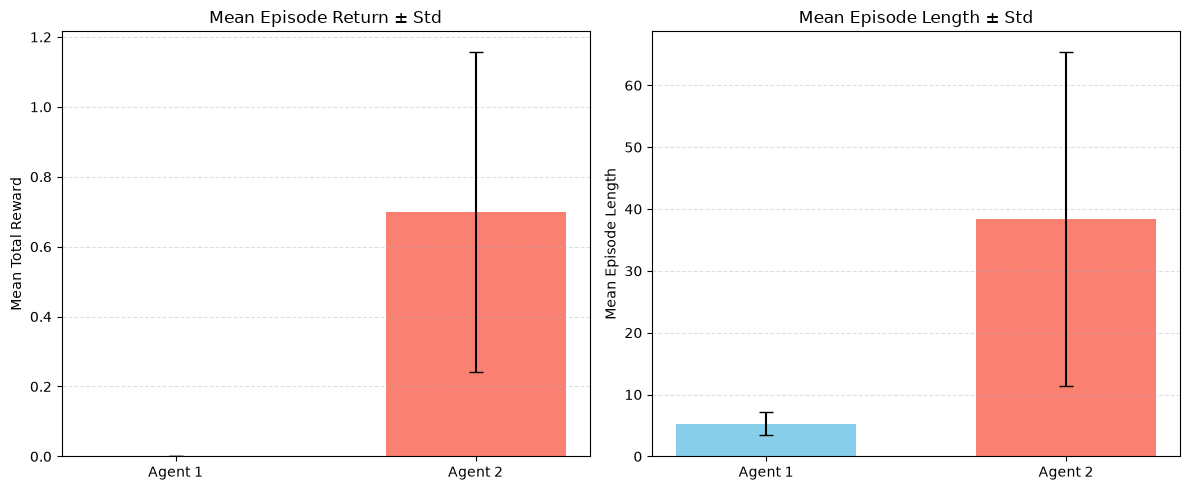

In [20]:
def compare_policy(
    rewards_run1, lengths_run1,
    rewards_run2, lengths_run2,
    label_run1="Agent 1", label_run2="Agent 2"
):
    """
    Compare two policy runs using mean return and mean episode length.

    Args:
        rewards_run1 (list): Episode rewards for run 1.
        lengths_run1 (list): Episode lengths for run 1.
        rewards_run2 (list): Episode rewards for run 2.
        lengths_run2 (list): Episode lengths for run 2.
        label_run1 (str): Label for run 1.
        label_run2 (str): Label for run 2.
    """

    mean_rewards = [np.mean(rewards_run1), np.mean(rewards_run2)]
    std_rewards  = [np.std(rewards_run1), np.std(rewards_run2)]

    mean_lengths = [np.mean(lengths_run1), np.mean(lengths_run2)]
    std_lengths  = [np.std(lengths_run1), np.std(lengths_run2)]

    labels = [label_run1, label_run2]
    x = np.arange(len(labels))
    width = 0.6

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Mean Rewards
    axes[0].bar(x, mean_rewards, yerr=std_rewards, capsize=5, width=width, color=['skyblue', 'salmon'])
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(labels)
    axes[0].set_ylabel("Mean Total Reward")
    axes[0].set_title("Mean Episode Return ± Std")
    axes[0].grid(True, axis="y", linestyle="--", alpha=0.4)

    # Mean Episode Lengths
    axes[1].bar(x, mean_lengths, yerr=std_lengths, capsize=5, width=width, color=['skyblue', 'salmon'])
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(labels)
    axes[1].set_ylabel("Mean Episode Length")
    axes[1].set_title("Mean Episode Length ± Std")
    axes[1].grid(True, axis="y", linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()

compare_policy(agent_1_returns, agent_1_lengths, agent_2_returns, agent_2_lengths)

15. Explique quais fatores levaram às diferenças observadas entre as políticas obtidas no ambiente determinístico e no ambiente escorregadio.

As diferenças ocorrem principalmente devido à natureza estocástica do ambiente escorregadio. No ambiente determinístico, o agente sempre se movimenta na direção escolhida, então pode escolher caminhos mais diretos até o objetivo. Já no ambiente escorregadio, existe apenas 1/3 de chance de o agente seguir na direção desejada e 2/3 de se mover em uma direção perpendicular. Isso faz com que ações em estados próximos a buracos tenham um valor esperado menor, pois existe uma maior chance de o agente cair. Desse modo, a política passa a apresentar uma preferência por movimentações mais seguras, priorizando ações que diminuam a probabilidade de cair em um buraco, mesmo que isso resulte em um caminho mais longo.


16. Quais estratégias poderiam ser adotadas para tornar o comportamento do agente menos conservador quando treinado no ambiente escorregadio?

Algumas estratégias podem ser adotadas para tornar o agente menos conservador. Uma delas seria adicionar uma penalidade a cada passo, fazendo com que o agente valorize caminhos mais curtos e evitando que permaneça repetindo movimentos, como ficar batendo na parede. Além disso, reduzir o fator de desconto faria com que recompensas futuras tivessem menos influência no valor das ações, podendo levar o agente a priorizar recompensas mais imediatas e, consequentemente, ações mais diretas em direção ao objetivo.
